# Phase 1 – Bayesian-optimised baseline (Barrow, BRW)

Same as the MLO notebook for Barrow. Input: data/processed/Imputed_BasePaper_BRW.csv. Results are printed in the notebook output (no CSV written).

**Part of:** Patidar & Patidar, *Predicting Daily Atmospheric CO$_2$ at Mauna Loa and Barrow: Trend-Aware Preprocessing and Chronological Validation* (JGR: Atmospheres, submitted). See the repository README for the run order.

Run from the `notebooks/` folder. Requires the packages in `requirements.txt`.


In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU Name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU Name: Tesla T4


In [2]:
# Google Drive mounting removed: all paths are relative to the repository.
# Run this notebook from the `notebooks/` folder.
import os
print('Working directory:', os.getcwd())

Mounted at /content/drive


In [4]:
import pandas as pd
file_path = "../data/processed/Imputed_BasePaper_BRW.csv"
data = pd.read_csv(file_path)
data.columns=data.columns.str.strip()
print(data.shape)
data.head()

(13332, 6)


,year,month,day,CO2_value,CH4_value,N2O_value
0,1987,8,7,341.82,1754.820000,305.399
1,1987,8,8,341.75,1756.620000,305.848
2,1987,8,9,340.39,1762.523333,306.463
3,1987,8,10,339.79,1774.100000,304.934
4,1987,8,11,338.81,1783.820000,306.161


In [5]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 6.2 MB/s eta 0:00:00


Using device: cuda
GPU Name: Tesla T4
Best parameters found:  OrderedDict({'max_depth': 24, 'max_features': 1, 'min_samples_leaf': 1, 'min_samples_split': 13, 'n_estimators': 1000})
Best cross-validation R2 score:  -25.77128149057102
Mean cross-validated MSE on training set:  25.77128149057102
Mean cross-validated R2 on training set:  0.9473263320526538
Mean Squared Error on test set:  24.032862443079964
R² on test set:  0.9507677615809049


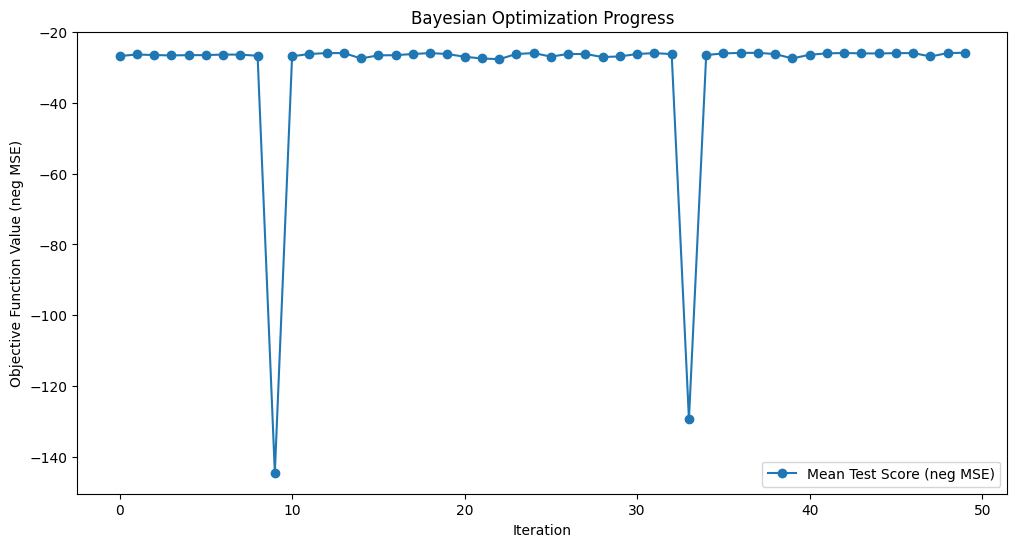

In [7]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Real, Integer
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU Name:", torch.cuda.get_device_name(0))


# 分离特征值和目标值
X = data[['CH4_value', 'N2O_value']]
y = data['CO2_value']

# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 定义随机森林模型
rf = RandomForestRegressor(random_state=42)

# 定义超参数搜索空间
param_space = {
    'n_estimators': Integer(10, 1000),
    'max_depth': Integer(1, 50),
    'min_samples_split': Integer(2, 20),
    'min_samples_leaf': Integer(1, 20),
    'max_features': Integer(1, X.shape[1])
}

# 定义贝叶斯搜索
opt = BayesSearchCV(
    estimator=rf,
    search_spaces=param_space,
    n_iter=50,  # 迭代次数，可以根据需要调整
    cv=5,  # 在训练集上进行5折交叉验证
    n_jobs=-1,
    random_state=42,
    scoring='neg_mean_squared_error'  # 使用负均方误差作为优化目标
)

# 在训练集上执行优化
opt.fit(X_train, y_train)

# 输出最佳参数
print("Best parameters found: ", opt.best_params_)
print("Best cross-validation R2 score: ", opt.best_score_)

# 使用最佳模型在训练集上进行交叉验证评分
cv_results_mse = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
mean_cv_mse = -cv_results_mse.mean()
print("Mean cross-validated MSE on training set: ", mean_cv_mse)

cv_results_r2 = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='r2')
mean_cv_r2 = cv_results_r2.mean()
print("Mean cross-validated R2 on training set: ", mean_cv_r2)

# 使用最佳模型在测试集上进行预测
y_pred = opt.best_estimator_.predict(X_test)

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test, y_pred)
print("R² on test set: ", r2_test)

# 获取优化过程的结果
results = opt.cv_results_

# 可视化优化过程
plt.figure(figsize=(12, 6))

# 绘制优化过程中目标函数的值
plt.plot(results['mean_test_score'], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()


Best parameters found:  OrderedDict({'max_depth': 27, 'max_features': 2, 'min_samples_leaf': 20, 'min_samples_split': 20})
Best cross-validation R2 score:  -29.241955314143354
Mean cross-validated MSE on training set:  29.241955314143354
Mean cross-validated R2 on training set:  0.9402411608883237
Mean Squared Error on test set:  27.039056926664035
R² on test set:  0.944609457138373


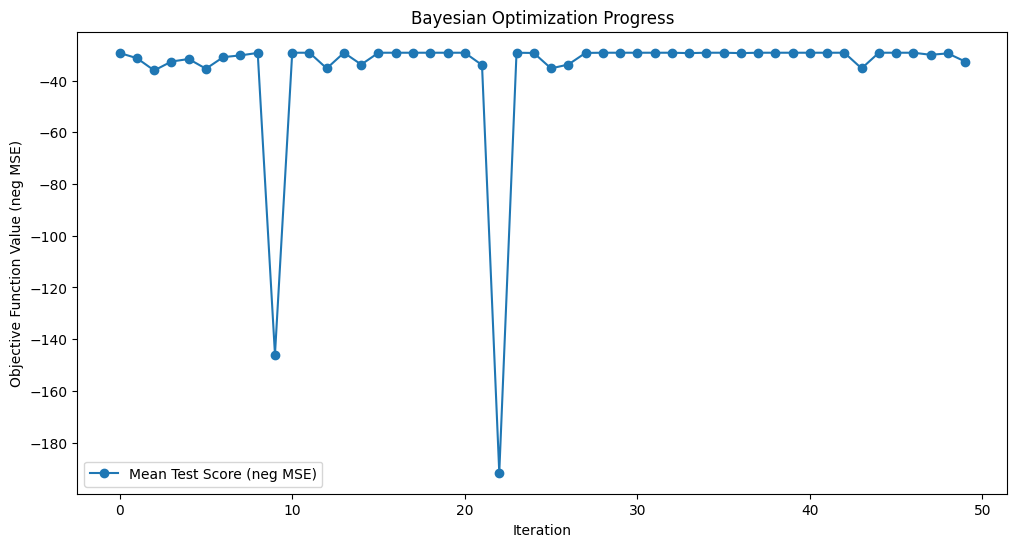

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from skopt import BayesSearchCV
from skopt.space import Real, Integer
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score


# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 定义决策树回归模型
dt = DecisionTreeRegressor(random_state=42)

# 定义超参数搜索空间
param_space = {
    'max_depth': Integer(1, 50),
    'min_samples_split': Integer(2, 20),
    'min_samples_leaf': Integer(1, 20),
    'max_features': Integer(1, X.shape[1])
}

# 定义贝叶斯搜索
opt = BayesSearchCV(
    estimator=dt,
    search_spaces=param_space,
    n_iter=50,  # 迭代次数，可以根据需要调整
    cv=5,  # 在训练集上进行5折交叉验证
    n_jobs=-1,
    random_state=42,
    scoring='neg_mean_squared_error'  # 使用负均方误差作为优化目标
)

# 在训练集上执行优化
opt.fit(X_train, y_train)

# 输出最佳参数
print("Best parameters found: ", opt.best_params_)
print("Best cross-validation R2 score: ", opt.best_score_)

# 使用最佳模型在训练集上进行交叉验证评分
cv_results_mse = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
mean_cv_mse = -cv_results_mse.mean()
print("Mean cross-validated MSE on training set: ", mean_cv_mse)

cv_results_r2 = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='r2')
mean_cv_r2 = cv_results_r2.mean()
print("Mean cross-validated R2 on training set: ", mean_cv_r2)

# 使用最佳模型在测试集上进行预测
y_pred = opt.best_estimator_.predict(X_test)

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test, y_pred)
print("R² on test set: ", r2_test)

# 获取优化过程的结果
results = opt.cv_results_

# 可视化优化过程
plt.figure(figsize=(12, 6))

# 绘制优化过程中目标函数的值
plt.plot(results['mean_test_score'], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters found: 
  colsample_bytree: 1.0
  learning_rate: 0.005395247478219331
  max_depth: 50
  min_child_weight: 1
  n_estimators: 1000
  subsample: 0.1
Best cross-validation R2 score:  -26.61517190795571
Mean cross-validated MSE on training set:  26.61517190795571
Mean cross-validated R2 on training set:  0.9456028377905007
Mean Squared Error on test set:  24.934405752385285
R² on test set:  0.9489209156109759


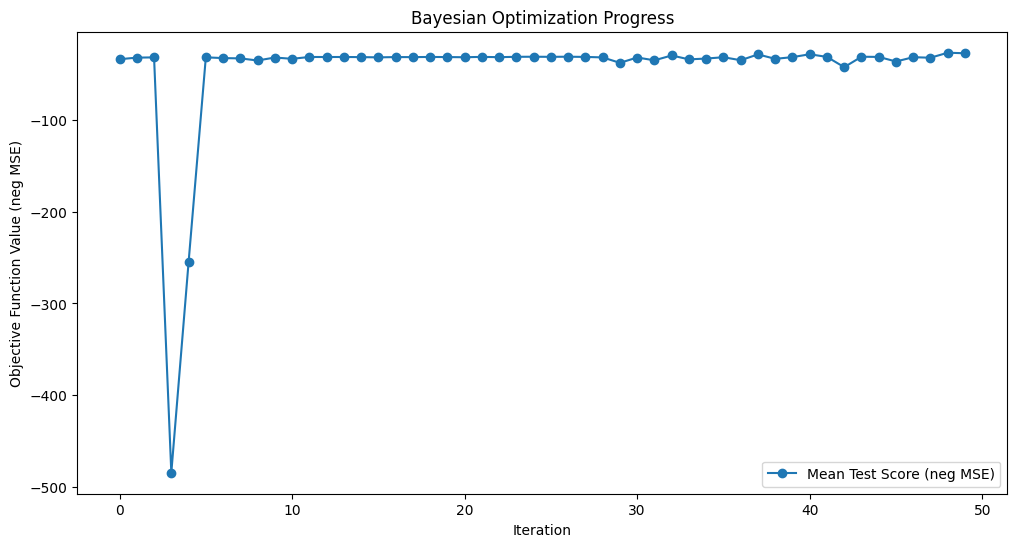

In [8]:
import pandas as pd
import xgboost as xgb
from skopt import BayesSearchCV
from skopt.space import Real, Integer
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score

# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 定义XGBoost回归模型
xgbr = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')

# 定义超参数搜索空间
param_space = {
    'n_estimators': Integer(50, 1000),
    'max_depth': Integer(1, 50),
    'learning_rate': Real(1e-6, 1.0, 'log-uniform'),
    'subsample': Real(0.1, 1.0),
    'colsample_bytree': Real(0.1, 1.0),
    'min_child_weight': Integer(1, 10)
}

# 定义贝叶斯搜索
opt = BayesSearchCV(
    estimator=xgbr,
    search_spaces=param_space,
    n_iter=50,  # 迭代次数，可以根据需要调整
    cv=5,  # 在训练集上进行5折交叉验证
    n_jobs=-1,
    random_state=42,
    scoring='neg_mean_squared_error'  # 使用负均方误差作为优化目标
)

# 在训练集上执行优化
opt.fit(X_train, y_train)

# 输出最佳参数
print("Best parameters found: ")
for param, value in opt.best_params_.items():
    print(f"  {param}: {value}")
print("Best cross-validation R2 score: ", opt.best_score_)

# 使用最佳模型在训练集上进行交叉验证评分
cv_results_mse = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
mean_cv_mse = -cv_results_mse.mean()
print("Mean cross-validated MSE on training set: ", mean_cv_mse)

cv_results_r2 = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='r2')
mean_cv_r2 = cv_results_r2.mean()
print("Mean cross-validated R2 on training set: ", mean_cv_r2)

# 使用最佳模型在测试集上进行预测
y_pred = opt.best_estimator_.predict(X_test)

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test, y_pred)
print("R² on test set: ", r2_test)

# 获取优化过程的结果
results = opt.cv_results_

# 可视化优化过程
plt.figure(figsize=(12, 6))

# 绘制优化过程中目标函数的值
plt.plot(results['mean_test_score'], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()


Best parameters found: 
  max_depth: 27
  max_features: 2
  min_samples_leaf: 20
  min_samples_split: 20
Best cross-validation R2 score:  -29.241955314143354
Mean cross-validated MSE on training set:  29.241955314143354
Mean cross-validated R2 on training set:  0.9402411608883237
Mean Squared Error on test set:  27.039056926664035
R² on test set:  0.944609457138373


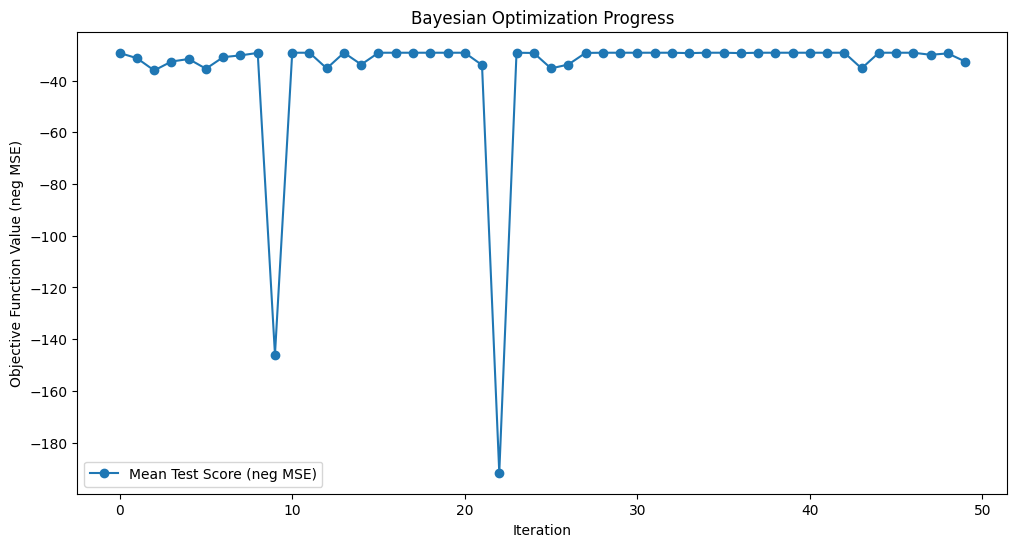

In [ ]:

# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 定义决策树回归模型
dt = DecisionTreeRegressor(random_state=42)

# 定义超参数搜索空间
param_space = {
    'max_depth': Integer(1, 50),
    'min_samples_split': Integer(2, 20),
    'min_samples_leaf': Integer(1, 20),
    'max_features': Integer(1, X.shape[1])
}

# 定义贝叶斯搜索
opt = BayesSearchCV(
    estimator=dt,
    search_spaces=param_space,
    n_iter=50,  # 迭代次数，可以根据需要调整
    cv=5,  # 在训练集上进行5折交叉验证
    n_jobs=-1,
    random_state=42,
    scoring='neg_mean_squared_error'  # 使用负均方误差作为优化目标
)

# 在训练集上执行优化
opt.fit(X_train, y_train)

# 输出最佳参数
print("Best parameters found: ")
for param, value in opt.best_params_.items():
    print(f"  {param}: {value}")
print("Best cross-validation R2 score: ", opt.best_score_)

# 使用最佳模型在训练集上进行交叉验证评分
cv_results_mse = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
mean_cv_mse = -cv_results_mse.mean()
print("Mean cross-validated MSE on training set: ", mean_cv_mse)

cv_results_r2 = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='r2')
mean_cv_r2 = cv_results_r2.mean()
print("Mean cross-validated R2 on training set: ", mean_cv_r2)

# 使用最佳模型在测试集上进行预测
y_pred = opt.best_estimator_.predict(X_test)

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test, y_pred)
print("R² on test set: ", r2_test)

# 获取优化过程的结果
results = opt.cv_results_

# 可视化优化过程
plt.figure(figsize=(12, 6))

# 绘制优化过程中目标函数的值
plt.plot(results['mean_test_score'], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()

Best parameters found: 
  max_depth: 24
  max_features: 1
  min_samples_leaf: 1
  min_samples_split: 13
  n_estimators: 1000
Best cross-validation R2 score:  -25.77128149057102
Mean cross-validated MSE on training set:  25.77128149057102
Mean cross-validated R2 on training set:  0.9473263320526538
Mean Squared Error on test set:  24.032862443079964
R² on test set:  0.9507677615809049


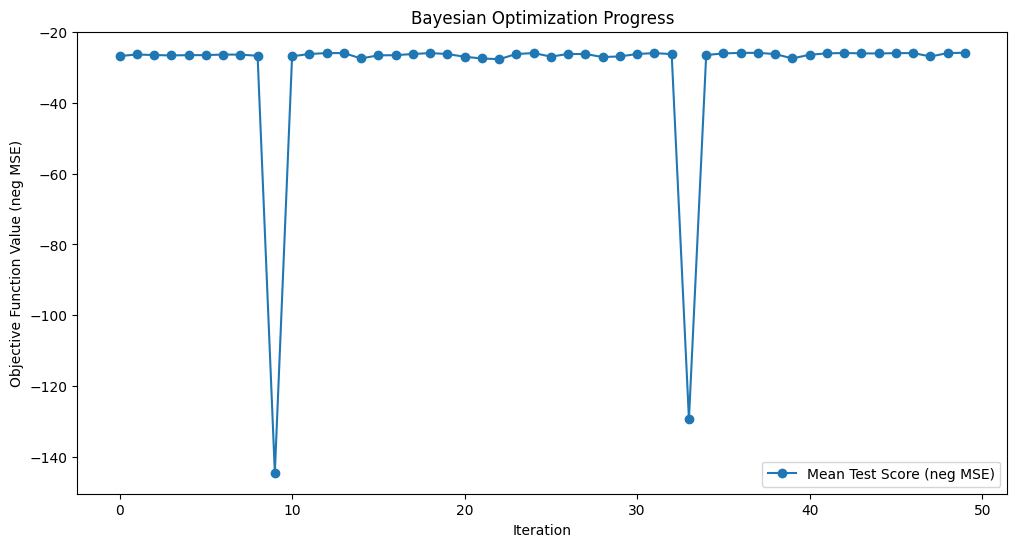

In [ ]:
# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 定义随机森林模型
rf = RandomForestRegressor(random_state=42)

# 定义超参数搜索空间
param_space = {
    'n_estimators': Integer(10, 1000),
    'max_depth': Integer(1, 50),
    'min_samples_split': Integer(2, 20),
    'min_samples_leaf': Integer(1, 20),
    'max_features': Integer(1, X.shape[1])
}

# 定义贝叶斯搜索
opt = BayesSearchCV(
    estimator=rf,
    search_spaces=param_space,
    n_iter=50,  # 迭代次数，可以根据需要调整
    cv=5,  # 在训练集上进行5折交叉验证
    n_jobs=-1,
    random_state=42,
    scoring='neg_mean_squared_error'  # 使用负均方误差作为优化目标
)

# 在训练集上执行优化
opt.fit(X_train, y_train)

# 输出最佳参数
print("Best parameters found: ")
for param, value in opt.best_params_.items():
    print(f"  {param}: {value}")
print("Best cross-validation R2 score: ", opt.best_score_)

# 使用最佳模型在训练集上进行交叉验证评分
cv_results_mse = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
mean_cv_mse = -cv_results_mse.mean()
print("Mean cross-validated MSE on training set: ", mean_cv_mse)

cv_results_r2 = cross_val_score(opt.best_estimator_, X_train, y_train, cv=5, scoring='r2')
mean_cv_r2 = cv_results_r2.mean()
print("Mean cross-validated R2 on training set: ", mean_cv_r2)

# 使用最佳模型在测试集上进行预测
y_pred = opt.best_estimator_.predict(X_test)

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test, y_pred)
print("R² on test set: ", r2_test)

# 获取优化过程的结果
results = opt.cv_results_

# 可视化优化过程
plt.figure(figsize=(12, 6))

# 绘制优化过程中目标函数的值
plt.plot(results['mean_test_score'], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()

In [ ]:
!pip install bayesian-optimization

|   iter    |  target   | lstm_u... | learni... | batch_... |  epochs   |
-------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
| 1         | -26.79477 | 43.708610 | 0.0950719 | 97.983321 | 63.879263 |


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
| 2         | -2.519822 | 24.041677 | 0.0156078 | 22.505364 | 87.955853 |


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (43 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
| 25        | -509.9078 | 34.562203 | 0.1       | 17.952622 | 83.779369 |
Best parameters found: 
  lstm_units: 24.041677639819287
  learning_rate: 0.015607892088416904
  batch_size: 22.505364562838338
  epochs: 87.95585311974416


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Mean Squared Error on test set:  2.599339216967899
R² on test set:  0.9946751541409202


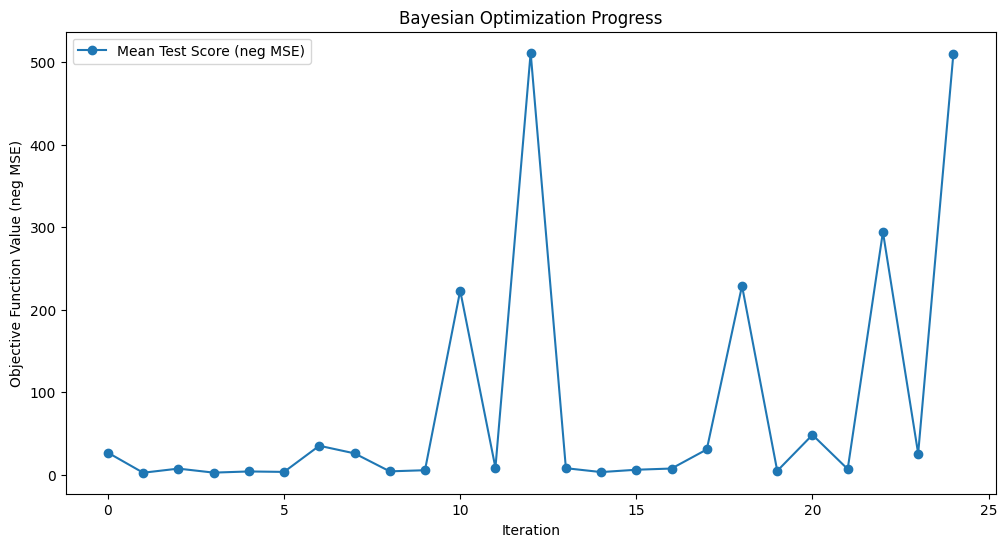

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from bayes_opt import BayesianOptimization
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# 假设数据中有日期特征，命名为 'Year', 'Month', 'Day'
# 分离特征值和目标值
X = data[['year', 'month', 'day', 'CH4_value', 'N2O_value',]].values
y = data['CO2_value'].values

# 标准化数据
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))

# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

# 将数据重新调整为3D形状，以适应LSTM输入要求
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 定义LSTM模型
def create_model(lstm_units, learning_rate):
    model = Sequential()
    model.add(LSTM(units=int(lstm_units), activation='relu', input_shape=(X_train.shape[1], 1)))
    model.add(Dense(1))
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse')
    return model

# 定义目标函数
def train_model(lstm_units, learning_rate, batch_size, epochs):
    model = create_model(lstm_units, learning_rate)
    model.fit(X_train, y_train, epochs=int(epochs), batch_size=int(batch_size), verbose=0)
    y_pred_scaled = model.predict(X_test)
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
    y_test_unscaled = scaler_y.inverse_transform(y_test.reshape(-1, 1))
    mse = mean_squared_error(y_test_unscaled, y_pred)
    return -mse  # 目标是最小化均方误差，所以返回负值

# 定义贝叶斯优化参数空间
pbounds = {
    'lstm_units': (10, 100),
    'learning_rate': (1e-5, 1e-1),
    'batch_size': (16, 128),
    'epochs': (10, 100)
}

# 初始化贝叶斯优化器
optimizer = BayesianOptimization(
    f=train_model,
    pbounds=pbounds,
    random_state=42
)

# 执行贝叶斯优化
optimizer.maximize(init_points=5, n_iter=20)

# 输出最佳参数
print("Best parameters found: ")
for param, value in optimizer.max['params'].items():
    print(f"  {param}: {value}")

# 使用最佳模型在训练集上进行评估
best_params = optimizer.max['params']
model = create_model(best_params['lstm_units'], best_params['learning_rate'])
model.fit(X_train, y_train, epochs=int(best_params['epochs']), batch_size=int(best_params['batch_size']), verbose=0)

# 使用最佳模型在测试集上进行预测
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
y_test_unscaled = scaler_y.inverse_transform(y_test.reshape(-1, 1))

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test_unscaled, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test_unscaled, y_pred)
print("R² on test set: ", r2_test)

# 可视化优化过程
results = optimizer.res
plt.figure(figsize=(12, 6))
plt.plot([-r['target'] for r in results], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()


|   iter    |  target   | lstm_u... | learni... | batch_... |  epochs   |
-------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
| 1         | -5.666286 | 43.708610 | 0.0950719 | 97.983321 | 63.879263 |


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
| 2         | -2.818292 | 24.041677 | 0.0156078 | 22.505364 | 87.955853 |


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (43 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
| 25        | -130.4200 | 60.601646 | 1e-05     | 128.0     | 100.0     |
Best parameters found: 
  lstm_units: 62.577252449052814
  learning_rate: 0.03619454452069519
  batch_size: 17.356754076268995
  epochs: 96.84076442024437


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Mean Squared Error on test set:  3.1824760821725775
R² on test set:  0.9934805759567062


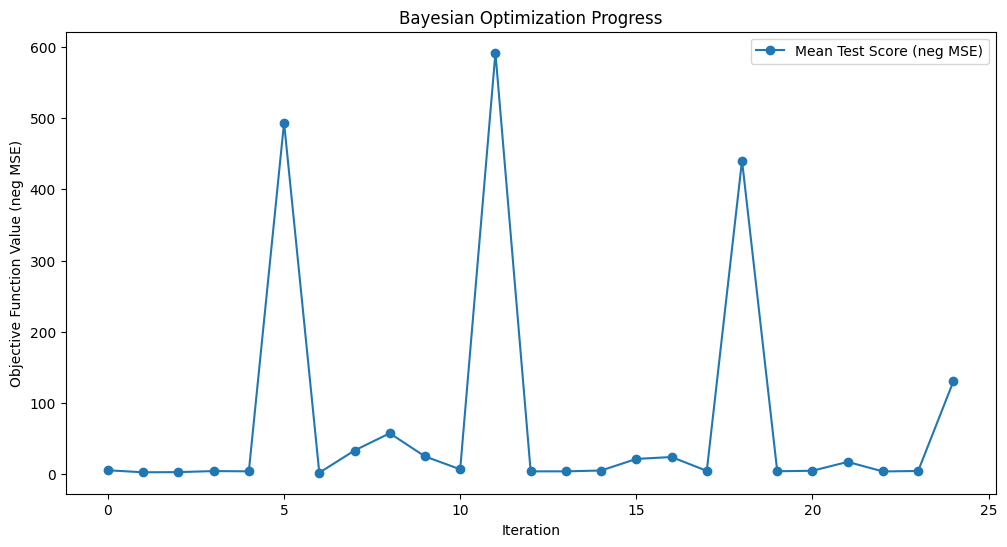

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense
from tensorflow.keras.optimizers import Adam
from bayes_opt import BayesianOptimization
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# 假设数据中有日期特征，命名为 'Year', 'Month', 'Day'
# 分离特征值和目标值
X = data[['year', 'month', 'day', 'CH4_value', 'N2O_value']].values
y = data['CO2_value'].values

# 标准化数据
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))

# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

# 将数据重新调整为3D形状，以适应LSTM输入要求
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 定义BiLSTM模型
def create_model(lstm_units, learning_rate):
    model = Sequential()
    model.add(Bidirectional(LSTM(units=int(lstm_units), activation='relu'), input_shape=(X_train.shape[1], 1)))
    model.add(Dense(1))
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse')
    return model

# 定义目标函数
def train_model(lstm_units, learning_rate, batch_size, epochs):
    model = create_model(lstm_units, learning_rate)
    model.fit(X_train, y_train, epochs=int(epochs), batch_size=int(batch_size), verbose=0)
    y_pred_scaled = model.predict(X_test)
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
    y_test_unscaled = scaler_y.inverse_transform(y_test.reshape(-1, 1))
    mse = mean_squared_error(y_test_unscaled, y_pred)
    return -mse  # 目标是最小化均方误差，所以返回负值

# 定义贝叶斯优化参数空间
pbounds = {
    'lstm_units': (10, 100),
    'learning_rate': (1e-5, 1e-1),
    'batch_size': (16, 128),
    'epochs': (10, 100)
}

# 初始化贝叶斯优化器
optimizer = BayesianOptimization(
    f=train_model,
    pbounds=pbounds,
    random_state=42
)

# 执行贝叶斯优化
optimizer.maximize(init_points=5, n_iter=20)

# 输出最佳参数
print("Best parameters found: ")
for param, value in optimizer.max['params'].items():
    print(f"  {param}: {value}")

# 使用最佳模型在训练集上进行评估
best_params = optimizer.max['params']
model = create_model(best_params['lstm_units'], best_params['learning_rate'])
model.fit(X_train, y_train, epochs=int(best_params['epochs']), batch_size=int(best_params['batch_size']), verbose=0)

# 使用最佳模型在测试集上进行预测
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
y_test_unscaled = scaler_y.inverse_transform(y_test.reshape(-1, 1))

# 计算测试集上的均方误差 (MSE)
mse_test = mean_squared_error(y_test_unscaled, y_pred)
print("Mean Squared Error on test set: ", mse_test)

# 计算测试集上的决定系数 (R²)
r2_test = r2_score(y_test_unscaled, y_pred)
print("R² on test set: ", r2_test)

# 可视化优化过程
results = optimizer.res
plt.figure(figsize=(12, 6))
plt.plot([-r['target'] for r in results], marker='o', label='Mean Test Score (neg MSE)')
plt.xlabel('Iteration')
plt.ylabel('Objective Function Value (neg MSE)')
plt.title('Bayesian Optimization Progress')
plt.legend()
plt.show()
